# Nighttime Lens Flare Removal — Experiment 2 (Fine-tuning)

This is a separate experiment based on the original `idse8` notebook. It retains the same dataset pipeline, preprocessing, fixed validation set design, and compact U-Net architecture, but fine-tunes the **Baseline 1 best model weights** with a revised training objective.

**Baseline 1 remains untouched.** All Experiment 2 checkpoints and results are written to a new directory.

Run this notebook from the top in a fresh Kaggle GPU session. The dataset archives are downloaded from the same Google Drive file IDs used by the original notebook.

**Before training:** in Section 12, provide the Google Drive file ID for `flare_removal_unet_best_weights.pth` (the 7.46 MB model weights file). You do not need to import Baseline 1's optimizer/checkpoint files: Experiment 2 intentionally starts with a fresh optimizer.


## 1. Environment and configuration

Enable **GPU T4** in Kaggle Settings before running. In the right-side **Settings → Session options → Persistence**, select **Files only** before starting this run. This preserves files under `/kaggle/working` across normal interactive-session restarts (best effort); it does not preserve GPU memory or guarantee recovery after a hard crash.

This notebook stores checkpoints, logs and datasets under `/kaggle/working`. The code independently saves a full training state every 100 batches, so a restarted session can rebuild the Python objects and resume from the latest checkpoint instead of restarting training. The Kaggle Persistence setting itself is a UI setting and cannot be enabled by Python code.


In [78]:
import os, sys, time, random, zipfile, shutil, subprocess, json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms

In [79]:
# Reproducibility and runtime configuration
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# This experiment is intended for Kaggle GPU (T4), not CPU training.
assert torch.cuda.is_available(), (
    "CUDA GPU is not available. In Kaggle, open Settings → Accelerator → GPU, "
    "then restart the session before continuing."
)
device = torch.device("cuda")
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

WORK = Path("/kaggle/working")
DATA_DIR = WORK / "flare_data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Google Drive file IDs supplied for the two dataset archives.
FLICKR_FILE_ID = "1mRPLMijWWtQ9-_6-f7wYgSyskPM6vb4G"
FLARE_FILE_ID = "1tJbK97sNLakOll6CJYU66AO_9E0xvA_0"
FLICKR_ZIP = DATA_DIR / "Flickr24K.zip"
FLARE_ZIP = DATA_DIR / "Flare7K++.zip"

# Experiment 2: fine-tune Baseline 1 rather than training from scratch.
IMAGE_SIZE = 256
BATCH_SIZE = 4
TRAIN_LIMIT = 4000
VAL_LIMIT = 500
EPOCHS = 5
LEARNING_RATE = 5e-5
NUM_WORKERS = 0

# Weighted reconstruction objective. The loss emphasizes pixels with larger
# synthetic corruption while keeping each image's mean pixel weight equal to 1.
FLARE_WEIGHT = 10.0

# Save a full recovery checkpoint every N training batches (100 batches was
# about 1.6 minutes in the previous T4 run).
CHECKPOINT_EVERY_BATCHES = 100
EARLY_STOPPING_PATIENCE = 4

# New run directory prevents accidentally loading incompatible older checkpoints.
RUN_DIR = WORK / "flare_unet_experiment_2"
RUN_DIR.mkdir(parents=True, exist_ok=True)
print("Experiment 2 configuration initialised.")
print("Dataset directory:", DATA_DIR)
print("Run directory:", RUN_DIR)


PyTorch: 2.11.0+cu130
GPU: Tesla T4
Experiment 2 configuration initialised.
Dataset directory: /kaggle/working/flare_data
Run directory: /kaggle/working/flare_unet_experiment_2


## 2. Install download and evaluation utilities

Kaggle's PyTorch, torchvision, NumPy and matplotlib are already supplied by the image. We install only `gdown` for Google Drive downloads and `scikit-image` for SSIM/PSNR evaluation.

In [80]:
%pip install -q gdown scikit-image
import gdown
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
print("gdown and scikit-image are ready.")

Note: you may need to restart the kernel to use updated packages.
gdown and scikit-image are ready.


## 3. Download the datasets

This cell checks existing files first. If a ZIP already exists and is a valid archive, it will not download it again. If Google Drive permissions prevent download, make sure both files are accessible to anyone with the link.

In [81]:
def valid_zip(path):
    return path.exists() and path.stat().st_size > 1_000_000 and zipfile.is_zipfile(path)

def download_drive_file(file_id, output_path):
    if valid_zip(output_path):
        print(f"Using existing archive: {output_path.name} ({output_path.stat().st_size/1024**3:.2f} GB)")
        return
    if output_path.exists():
        output_path.unlink()
    url = f"https://drive.google.com/uc?id={file_id}"
    result = gdown.download(url, str(output_path), quiet=False, fuzzy=True)
    if result is None or not valid_zip(output_path):
        raise RuntimeError(
            f"Download failed or file is not a valid ZIP: {output_path}. "
            "Check Google Drive sharing permissions and retry."
        )
    print(f"Downloaded {output_path.name}: {output_path.stat().st_size/1024**3:.2f} GB")

download_drive_file(FLICKR_FILE_ID, FLICKR_ZIP)
download_drive_file(FLARE_FILE_ID, FLARE_ZIP)

Using existing archive: Flickr24K.zip (1.12 GB)
Using existing archive: Flare7K++.zip (3.72 GB)


## 4. Extract and verify the archives

Extraction is skipped when the expected top-level folder is already present. This avoids re-extracting several gigabytes if the cell is rerun.

In [82]:
def find_named_dir(root, target_name):
    root = Path(root)
    matches = [p for p in root.rglob(target_name) if p.is_dir()]
    if not matches:
        return None
    # Prefer the shallowest match.
    return sorted(matches, key=lambda p: len(p.parts))[0]

def safe_extract(zip_path, destination):
    with zipfile.ZipFile(zip_path) as zf:
        bad_member = zf.testzip()
        if bad_member is not None:
            raise RuntimeError(f"Corrupt archive member: {bad_member}")
        zf.extractall(destination)

flickr_dir = find_named_dir(DATA_DIR, "Flickr24K")
if flickr_dir is None:
    print("Extracting Flickr24K...")
    safe_extract(FLICKR_ZIP, DATA_DIR)
else:
    print("Flickr24K already extracted:", flickr_dir)

flare7k_dir = find_named_dir(DATA_DIR, "Flare7K")
if flare7k_dir is None:
    print("Extracting Flare7K++...")
    safe_extract(FLARE_ZIP, DATA_DIR)
else:
    print("Flare7K++ already extracted.")

# Re-discover after extraction; Flare7K is nested inside Flare7Kpp/Flare7K.
flickr_dir = find_named_dir(DATA_DIR, "Flickr24K")
flare7k_dir = find_named_dir(DATA_DIR, "Flare7K")
assert flickr_dir is not None, "Could not find Flickr24K folder after extraction."
assert flare7k_dir is not None, "Could not find Flare7K folder after extraction."

scattering_root = flare7k_dir / "Scattering_Flare"
reflective_root = flare7k_dir / "Reflective_Flare"
assert scattering_root.is_dir(), f"Missing {scattering_root}"
assert reflective_root.is_dir(), f"Missing {reflective_root}"

print("Flickr folder:", flickr_dir)
print("Flare7K folder:", flare7k_dir)
print("Scattering categories:", sorted(p.name for p in scattering_root.iterdir() if p.is_dir()))

Flickr24K already extracted: /kaggle/working/flare_data/Flickr24K
Flare7K++ already extracted.
Flickr folder: /kaggle/working/flare_data/Flickr24K
Flare7K folder: /kaggle/working/flare_data/Flare7Kpp/Flare7K
Scattering categories: ['Compound_Flare', 'Core', 'Glare_with_shimmer', 'Light_Source', 'Streak']


## 5. Clone the official Flare7K repository

The repository is cloned into the new notebook's working directory. No previous notebook files are required.

In [83]:
REPO_DIR = WORK / "Flare7K"
if not (REPO_DIR / "data_loader.py").exists():
    if REPO_DIR.exists():
        shutil.rmtree(REPO_DIR)
    subprocess.run(
        ["git", "clone", "--depth", "1", "https://github.com/ykdai/Flare7K.git", str(REPO_DIR)],
        check=True
    )
assert (REPO_DIR / "data_loader.py").exists()
print("Official loader:", REPO_DIR / "data_loader.py")

Official loader: /kaggle/working/Flare7K/data_loader.py


## 6. Build the synthetic paired dataset

The official loader returns this tuple, in this exact order:

`clean_image, flare_image, corrupted_image, flare_mask, gamma`

It creates synthetic flare-corrupted samples on the fly. The five Flare7K scattering folders are loaded individually because the loader searches only the immediate directory passed to it. The Flare-R captured-pattern folders are also added when present in the archive.

In [84]:
from pathlib import Path

loader_path = Path("/kaggle/working/Flare7K/data_loader.py")

# Restore the original loader from GitHub.
import subprocess

subprocess.run(
    [
        "git", "checkout", "HEAD", "--", "data_loader.py"
    ],
    cwd="/kaggle/working/Flare7K",
    check=True
)

# Confirm that the original file is valid Python.
loader_code = loader_path.read_text()
compile(loader_code, str(loader_path), "exec")

print("Original data_loader.py restored successfully.")

Original data_loader.py restored successfully.


In [85]:
from pathlib import Path

loader_path = Path("/kaggle/working/Flare7K/data_loader.py")
code = loader_path.read_text()

old = """\t\t\treflective_img=adjust_gamma(reflective_img)
\t\t\tflare_img = torch.clamp(flare_img+reflective_img,min=0,max=1)"""

new = """\t\t\treflective_img=adjust_gamma(reflective_img)
\t\t\tif reflective_img.shape[-2:] != flare_img.shape[-2:]:
\t\t\t\treflective_img = torch.nn.functional.interpolate(
\t\t\t\t\treflective_img.unsqueeze(0),
\t\t\t\t\tsize=flare_img.shape[-2:],
\t\t\t\t\tmode="bilinear",
\t\t\t\t\talign_corners=False
\t\t\t\t).squeeze(0)
\t\t\tflare_img = torch.clamp(flare_img+reflective_img,min=0,max=1)"""

assert old in code, "Expected code block not found. No changes made."

code = code.replace(old, new, 1)

compile(code, str(loader_path), "exec")
loader_path.write_text(code)

print("Patch applied. Syntax check passed.")

Patch applied. Syntax check passed.


In [86]:
import sys
sys.path.insert(0, "/kaggle/working/Flare7K")

from data_loader import Flare_Image_Loader

print("Flare_Image_Loader imported successfully.")

Flare_Image_Loader imported successfully.


In [87]:
from torchvision import transforms

base_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.RandomCrop(IMAGE_SIZE, pad_if_needed=True),
    transforms.RandomHorizontalFlip()
])

flare_transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.RandomAffine(
        degrees=(0, 360),
        scale=(0.8, 1.5),
        translate=(0.20, 0.20),
        shear=(-20, 20)
    ),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))
])

print("Both transforms defined successfully.")

Both transforms defined successfully.


In [88]:
for name in ["flickr_dir", "base_transform", "flare_transform", "IMAGE_SIZE"]:
    print(f"{name}: {'defined' if name in globals() else 'NOT defined'}")

flickr_dir: defined
base_transform: defined
flare_transform: defined
IMAGE_SIZE: defined


In [89]:
sys.path.insert(0, str(REPO_DIR))

from data_loader import Flare_Image_Loader


# Background augmentation: resize while preserving aspect ratio, then crop.
base_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.RandomCrop(IMAGE_SIZE, pad_if_needed=True),
    transforms.RandomHorizontalFlip()
])

# Flare augmentation: randomise scale, position, orientation and reflections.
# The official loader applies its own flare synthesis/gamma/noise operations afterwards.
flare_transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.RandomAffine(
        degrees=(0, 360),
        scale=(0.8, 1.5),
        translate=(0.20, 0.20),
        shear=(-20, 20)
    ),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))
])

dataset = Flare_Image_Loader(
    image_path=str(flickr_dir),
    transform_base=base_transform,
    transform_flare=flare_transform,
    mask_type="luminance"
)

scattering_categories = [
    "Light_Source", "Compound_Flare", "Glare_with_shimmer", "Core", "Streak"
]
for category in scattering_categories:
    category_path = scattering_root / category
    assert category_path.is_dir(), f"Missing scattering category: {category_path}"
    dataset.load_scattering_flare(category, str(category_path))

dataset.load_reflective_flare("Reflective", str(reflective_root))

# Flare-R contains 962 real-captured flare patterns. Add its two pattern
# folders to the same scattering pool when the extracted archive includes them.
flare_r_root = flare7k_dir.parent / "Flare-R"
flare_r_loaded = []
for category in ["Compound_Flare", "Light_Source"]:
    category_path = flare_r_root / category
    if category_path.is_dir():
        dataset.load_scattering_flare(f"FlareR_{category}", str(category_path))
        flare_r_loaded.append(category)
print("Flare-R categories loaded:", flare_r_loaded if flare_r_loaded else "not present")

print("Background images:", len(dataset.data_list))
print("Scattering flare patterns:", len(dataset.flare_list))
print("Reflective flare patterns:", len(dataset.reflective_list))
print("Dataset length:", len(dataset))
assert len(dataset.data_list) > 0
assert len(dataset.flare_list) > 0
assert len(dataset.reflective_list) > 0

Base Image Loaded with examples: 23949
Scattering Flare Image: Light_Source  is loaded successfully with examples 5000
Now we have 5000 scattering flare images
Scattering Flare Image: Compound_Flare  is loaded successfully with examples 5000
Now we have 10000 scattering flare images
Scattering Flare Image: Glare_with_shimmer  is loaded successfully with examples 5000
Now we have 15000 scattering flare images
Scattering Flare Image: Core  is loaded successfully with examples 5000
Now we have 20000 scattering flare images
Scattering Flare Image: Streak  is loaded successfully with examples 5000
Now we have 25000 scattering flare images
Reflective Flare Image: Reflective  is loaded successfully with examples 2000
Now we have 2000 refelctive flare images
Scattering Flare Image: FlareR_Compound_Flare  is loaded successfully with examples 962
Now we have 25962 scattering flare images
Scattering Flare Image: FlareR_Light_Source  is loaded successfully with examples 962
Now we have 26924 scatt

In [90]:
sample = dataset[0]

print("Number of returned values:", len(sample))

for i, item in enumerate(sample):
    if torch.is_tensor(item):
        print(f"Output {i}: shape={tuple(item.shape)}, dtype={item.dtype}")
    else:
        print(f"Output {i}: {item}")

Number of returned values: 5
Output 0: shape=(3, 256, 256), dtype=torch.float32
Output 1: shape=(3, 256, 256), dtype=torch.float32
Output 2: shape=(3, 256, 256), dtype=torch.float32
Output 3: shape=(3, 256, 256), dtype=torch.float32
Output 4: 1.949816047538945


In [91]:
clean_image, flare_image, corrupted_image, flare_mask, gamma = dataset[0]

input_image = corrupted_image
target_image = clean_image

print("Input shape:", input_image.shape)
print("Target shape:", target_image.shape)
print("Input range:", input_image.min().item(), input_image.max().item())
print("Target range:", target_image.min().item(), target_image.max().item())

Input shape: torch.Size([3, 256, 256])
Target shape: torch.Size([3, 256, 256])
Input range: 0.07643773406744003 1.0
Target range: 0.0 0.954298198223114


In [92]:
from torch.utils.data import DataLoader

BATCH_SIZE = 4

train_loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

batch = next(iter(train_loader))

clean, flare, corrupted, mask, gamma = batch

print("Clean:", clean.shape)
print("Flare:", flare.shape)
print("Corrupted:", corrupted.shape)
print("Mask:", mask.shape)
print("Gamma:", gamma.shape)

Clean: torch.Size([4, 3, 256, 256])
Flare: torch.Size([4, 3, 256, 256])
Corrupted: torch.Size([4, 3, 256, 256])
Mask: torch.Size([4, 3, 256, 256])
Gamma: torch.Size([4])


In [93]:
for name in ["FlareUNet", "UNet", "ResidualBlock", "DoubleConv"]:
    print(f"{name}: {'defined' if name in globals() else 'NOT defined'}")

FlareUNet: defined
UNet: NOT defined
ResidualBlock: NOT defined
DoubleConv: defined


## 7. Data-quality audit and visual inspection

This checks the actual tensors returned by the loader, not just filenames. Do not continue if the sample is not three-channel RGB, finite, or in the expected `[0,1]` range.

Flickr image modes (sample): Counter({'RGB': 300})
Scattering image modes (sample): Counter({'RGB': 300})
Reflective image modes (sample): Counter({'RGB': 300})
clean shape: (3, 256, 256) dtype: torch.float32 range: (0.0, 1.0) finite: True
flare shape: (3, 256, 256) dtype: torch.float32 range: (0.14231930673122406, 0.7304967045783997) finite: True
corrupted shape: (3, 256, 256) dtype: torch.float32 range: (0.14231930673122406, 1.0) finite: True
mask shape: (3, 256, 256) dtype: torch.float32 range: (0.0, 0.0) finite: True


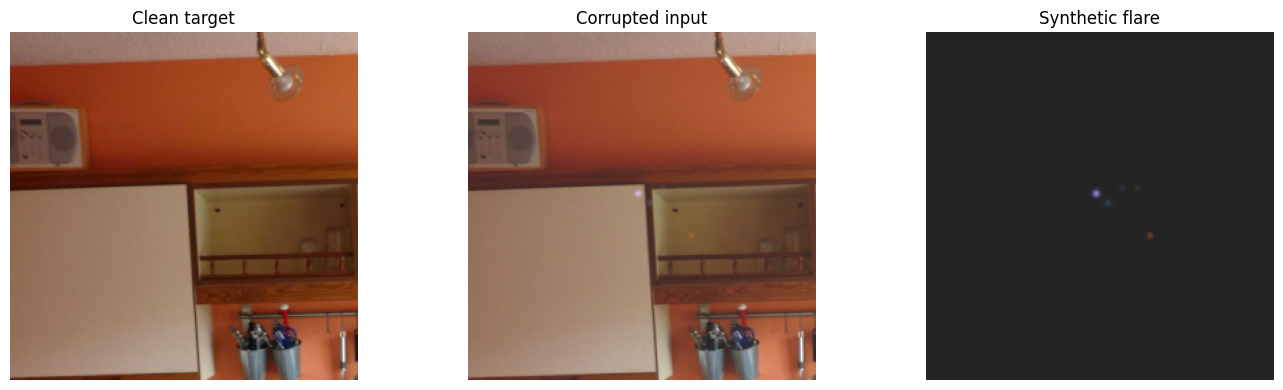

In [94]:
def count_image_modes(folder, limit=300):
    paths = []
    for ext in ("*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif"):
        paths.extend(Path(folder).glob(ext))
    counts = Counter()
    for p in paths[:limit]:
        try:
            with Image.open(p) as im:
                counts[im.mode] += 1
        except Exception as exc:
            print("Unreadable image:", p, exc)
    return counts

print("Flickr image modes (sample):", count_image_modes(flickr_dir))
print("Scattering image modes (sample):", count_image_modes(scattering_root / "Light_Source"))
print("Reflective image modes (sample):", count_image_modes(reflective_root))

clean0, flare0, corrupted0, mask0, gamma0 = dataset[0]
for name, tensor in [
    ("clean", clean0), ("flare", flare0),
    ("corrupted", corrupted0), ("mask", mask0)
]:
    print(name, "shape:", tuple(tensor.shape), "dtype:", tensor.dtype,
          "range:", (float(tensor.min()), float(tensor.max())),
          "finite:", bool(torch.isfinite(tensor).all()))

assert clean0.shape == (3, IMAGE_SIZE, IMAGE_SIZE), "Clean sample is not RGB 256x256."
assert flare0.shape == clean0.shape and corrupted0.shape == clean0.shape
assert torch.isfinite(clean0).all() and torch.isfinite(corrupted0).all()
assert float(clean0.min()) >= 0 and float(clean0.max()) <= 1
assert float(corrupted0.min()) >= 0 and float(corrupted0.max()) <= 1

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, img, title in zip(
    axes, [clean0, corrupted0, flare0],
    ["Clean target", "Corrupted input", "Synthetic flare"]
):
    ax.imshow(img.permute(1, 2, 0).cpu().numpy().clip(0, 1))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Split backgrounds into train and validation

We split the clean-background indices before selecting the smaller experiment subset. This prevents the same background index from appearing in both sets. Flare patterns are sampled randomly by the official loader when an item is generated.

In [95]:
all_indices = np.arange(len(dataset))
rng = np.random.default_rng(SEED)
rng.shuffle(all_indices)

validation_pool_size = max(1, int(0.20 * len(all_indices)))
validation_pool = all_indices[:validation_pool_size]
training_pool = all_indices[validation_pool_size:]

train_indices = training_pool[:min(TRAIN_LIMIT, len(training_pool))].tolist()
val_indices = validation_pool[:min(VAL_LIMIT, len(validation_pool))].tolist()

assert set(train_indices).isdisjoint(val_indices)
print("Training backgrounds:", len(train_indices))
print("Validation backgrounds:", len(val_indices))
print("Overlap:", len(set(train_indices).intersection(val_indices)))

Training backgrounds: 4000
Validation backgrounds: 500
Overlap: 0


## 9. Cache a fixed validation set and create DataLoaders

Only 500 validation samples are generated and cached. This is much faster and lighter than caching the full validation pool. Validation images remain identical between epochs.

In [96]:
class FixedValidationDataset(Dataset):
    def __init__(self, source_dataset, indices, seed=42):
        self.samples = []
        py_state = random.getstate()
        np_state = np.random.get_state()
        torch_state = torch.random.get_rng_state()

        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        try:
            for idx in indices:
                self.samples.append(source_dataset[int(idx)])
        finally:
            random.setstate(py_state)
            np.random.set_state(np_state)
            torch.random.set_rng_state(torch_state)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]

train_dataset = Subset(dataset, train_indices)
fixed_val_dataset = FixedValidationDataset(dataset, val_indices, seed=SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True
)
val_loader = DataLoader(
    fixed_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Fixed validation samples:", len(fixed_val_dataset))

Train batches: 1000
Validation batches: 125
Fixed validation samples: 500


## 10. Mandatory batch-order test

This is the key correctness check before training. The model input is the **third** returned tensor (`corrupted`); the target is the **first** (`clean`).

Clean: torch.Size([4, 3, 256, 256]) 0.0 1.0
Flare: torch.Size([4, 3, 256, 256]) 0.0 0.9988718628883362
Corrupted: torch.Size([4, 3, 256, 256]) 0.0 1.0


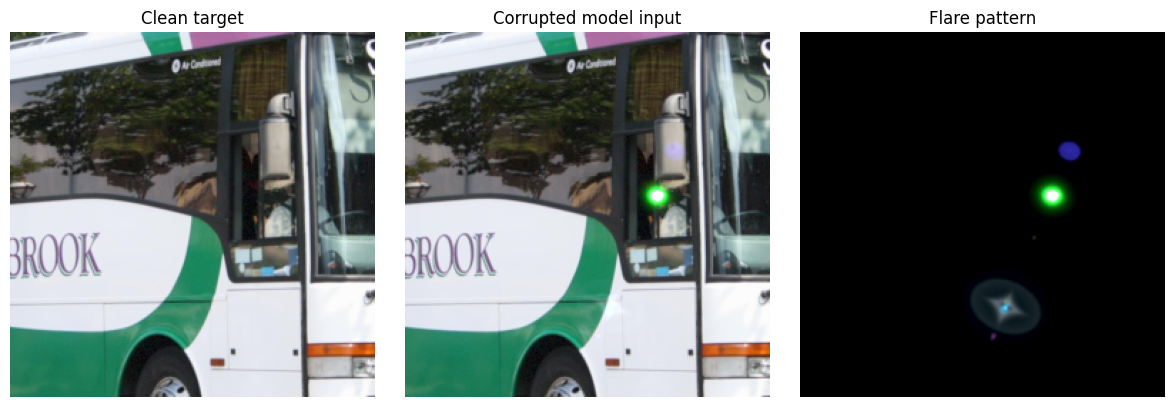

In [97]:
clean_b, flare_b, corrupted_b, mask_b, gamma_b = next(iter(train_loader))

print("Clean:", clean_b.shape, clean_b.min().item(), clean_b.max().item())
print("Flare:", flare_b.shape, flare_b.min().item(), flare_b.max().item())
print("Corrupted:", corrupted_b.shape, corrupted_b.min().item(), corrupted_b.max().item())

assert clean_b.shape == corrupted_b.shape == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
assert torch.isfinite(clean_b).all() and torch.isfinite(corrupted_b).all()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, title in zip(
    axes, [clean_b[0], corrupted_b[0], flare_b[0]],
    ["Clean target", "Corrupted model input", "Flare pattern"]
):
    ax.imshow(img.permute(1, 2, 0).numpy().clip(0, 1))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 11. Compact U-Net

This U-Net uses fewer feature channels than the earlier 32–512-channel version to reduce compute and memory use. It preserves the encoder-decoder structure and skip connections.

In [98]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)


class FlareUNet(nn.Module):
    """Predicts the flare residual; clean estimate = corrupted input - flare estimate."""
    def __init__(self):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.enc1 = DoubleConv(3, 16)
        self.enc2 = DoubleConv(16, 32)
        self.enc3 = DoubleConv(32, 64)
        self.enc4 = DoubleConv(64, 128)
        self.bottleneck = DoubleConv(128, 256)
        self.up4 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec4 = DoubleConv(256, 128)
        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec3 = DoubleConv(128, 64)
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = DoubleConv(64, 32)
        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = DoubleConv(32, 16)
        self.out = nn.Conv2d(16, 3, 1)
        # Initially predicts zero flare, so the initial clean estimate equals the input.
        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        flare_estimate = self.out(d1)
        clean_estimate = x - flare_estimate
        return clean_estimate, flare_estimate


model = FlareUNet().to(device)
parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable parameters:", f"{parameter_count:,}")
with torch.no_grad():
    test_clean, test_flare = model(torch.rand(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device))
assert test_clean.shape == test_flare.shape == (2, 3, IMAGE_SIZE, IMAGE_SIZE)

Trainable parameters: 1,942,611


## 12. Load Baseline 1 weights and create a fresh optimizer

This experiment starts from the **Baseline 1 best model weights** (best epoch 7), but uses a new optimizer, scheduler and AMP scaler. This is deliberate: we are fine-tuning the learned model parameters, not resuming Baseline 1's training run.

You only need `flare_removal_unet_best_weights.pth` (the 7.46 MB state-dict file). Do **not** import `best_model.pth` or `latest_checkpoint.pth` from Baseline 1; those contain the old optimizer/training state and are not used for this fresh experiment.

Paste the Google Drive file ID for the Baseline 1 weights in the next cell. Make sure the Drive file is shared so that the notebook can download it.


In [99]:
# Download Baseline 1's best weights from Google Drive.
# Paste the FILE ID from the share link for flare_removal_unet_best_weights.pth.
BASELINE1_DRIVE_FILE_ID = "1KieF7YW-A3GMqiCv4qbVQqdp2BPUM0bq"
BASELINE1_WEIGHTS = WORK / "flare_removal_unet_best_weights.pth"

if not BASELINE1_WEIGHTS.exists():
    if BASELINE1_DRIVE_FILE_ID == "PASTE_GOOGLE_DRIVE_FILE_ID_HERE":
        raise ValueError(
            "Before running this cell, replace BASELINE1_DRIVE_FILE_ID with "
            "the file ID from your Google Drive share link."
        )
    download_url = f"https://drive.google.com/uc?id={BASELINE1_DRIVE_FILE_ID}"
    downloaded = gdown.download(download_url, str(BASELINE1_WEIGHTS), quiet=False, fuzzy=True)
    if downloaded is None or not BASELINE1_WEIGHTS.exists():
        raise RuntimeError("Could not download Baseline 1 weights. Check the Drive link permissions.")

# The saved file is a model state_dict, not a full training checkpoint.
baseline_state = torch.load(BASELINE1_WEIGHTS, map_location=device, weights_only=True)
model.load_state_dict(baseline_state)
print("Loaded Baseline 1 best weights:", BASELINE1_WEIGHTS)
print("Model parameter tensors loaded:", len(baseline_state))

# Fresh optimizer state for Experiment 2 fine-tuning.
criterion = nn.L1Loss()  # Validation/checkpoint selection remains ordinary L1.
optimizer = Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

BEST_CHECKPOINT = RUN_DIR / "best_model.pth"
LATEST_CHECKPOINT = RUN_DIR / "latest_checkpoint.pth"
print("AMP enabled:", use_amp)
print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Run directory:", RUN_DIR)
print("Latest resumable checkpoint:", LATEST_CHECKPOINT)
print("Best validation checkpoint:", BEST_CHECKPOINT)


Loaded Baseline 1 best weights: /kaggle/working/flare_removal_unet_best_weights.pth
Model parameter tensors loaded: 118
AMP enabled: True
Learning rate: 5e-05
Epochs: 5
Run directory: /kaggle/working/flare_unet_experiment_2
Latest resumable checkpoint: /kaggle/working/flare_unet_experiment_2/latest_checkpoint.pth
Best validation checkpoint: /kaggle/working/flare_unet_experiment_2/best_model.pth


## 13. Training and validation functions

Training uses a spatially weighted L1 reconstruction objective. Validation reports ordinary L1 so that the checkpoint-selection metric remains interpretable and comparable with the unweighted input baseline. Training checkpoints are atomic and written at batch intervals.


In [100]:
from torch.utils.data._utils.collate import default_collate

def capture_rng_state():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }

def restore_rng_state(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if torch.cuda.is_available() and state.get("cuda") is not None:
        torch.cuda.set_rng_state_all(state["cuda"])

def current_run_config():
    return {
        "image_size": IMAGE_SIZE,
        "batch_size": BATCH_SIZE,
        "train_limit": TRAIN_LIMIT,
        "val_limit": VAL_LIMIT,
        "learning_rate": LEARNING_RATE,
        "flare_weight": FLARE_WEIGHT,
        "epochs": EPOCHS,
        "seed": SEED,
        "experiment": "experiment_2_finetune",
        "ordinary_l1_weight": 0.7,
        "weighted_l1_weight": 0.3,
        "low_flare_preservation_weight": 0.1,
    }

def atomic_torch_save(payload, destination):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(destination.suffix + ".tmp")
    torch.save(payload, temporary)
    # os.replace is atomic on the same filesystem: an interrupted write does
    # not destroy the previous valid checkpoint.
    os.replace(temporary, destination)

def make_checkpoint(
    current_epoch, next_batch, epoch_order, running_loss_sum, batches_done,
    history, best_val_loss, epochs_without_improvement, completed=False
):
    return {
        "format_version": 3,
        "config": current_run_config(),
        "current_epoch": int(current_epoch),
        # For epoch-boundary/best checkpoints, current_epoch points to the
        # next epoch, so the completed epoch is current_epoch - 1.
        "epoch": int(current_epoch - 1 if epoch_order is None else current_epoch),
        "val_loss": float(history["val_loss"][-1]) if history["val_loss"] else float("inf"),
        "next_batch": int(next_batch),
        "epoch_order": epoch_order,
        "running_loss_sum": float(running_loss_sum),
        "batches_done": int(batches_done),
        "history": history,
        "best_val_loss": float(best_val_loss),
        "epochs_without_improvement": int(epochs_without_improvement),
        "completed": bool(completed),
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "rng_state": capture_rng_state(),
    }

def save_latest_checkpoint(**kwargs):
    payload = make_checkpoint(**kwargs)
    atomic_torch_save(payload, LATEST_CHECKPOINT)

def train_one_batch(batch):
    model.train()
    clean, flare, corrupted, mask, gamma = batch
    clean = clean.to(device, non_blocking=True)
    corrupted = corrupted.to(device, non_blocking=True)

    # Actual synthetic corruption residual after the loader's image operations.
    actual_flare = (corrupted - clean).abs().mean(dim=1)

    # Per-image spatial weights: stronger corruption receives more emphasis.
    weights = 1.0 + FLARE_WEIGHT * actual_flare
    weights = weights / weights.mean(dim=(1, 2), keepdim=True).clamp_min(1e-8)

    # Lowest 40% of residual magnitudes are treated as low-flare pixels.
    # Penalising corrections there discourages unnecessary colour shifts.
    threshold = torch.quantile(
        actual_flare.flatten(1), 0.40, dim=1
    ).view(-1, 1, 1)
    low_flare_mask = (actual_flare <= threshold).float()

    optimizer.zero_grad(set_to_none=True)
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
        clean_prediction, flare_prediction = model(corrupted)

        pixel_loss = F.l1_loss(
            clean_prediction.float(), clean, reduction="none"
        ).mean(dim=1)

        ordinary_l1 = pixel_loss.mean()
        weighted_l1 = (pixel_loss * weights).mean()

        predicted_correction = flare_prediction.float().abs().mean(dim=1)
        preservation_loss = (
            predicted_correction * low_flare_mask
        ).sum() / low_flare_mask.sum().clamp_min(1.0)

        loss = (
            0.7 * ordinary_l1
            + 0.3 * weighted_l1
            + 0.1 * preservation_loss
        )

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()
    return float(loss.detach().float().item())

@torch.no_grad()
def validate_one_epoch():
    model.eval()
    running_loss = 0.0
    batch_count = 0
    for clean, flare, corrupted, mask, gamma in val_loader:
        clean = clean.to(device, non_blocking=True)
        corrupted = corrupted.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            clean_prediction, _ = model(corrupted)
            loss = criterion(clean_prediction.float(), clean)
        running_loss += loss.item()
        batch_count += 1
    return running_loss / max(batch_count, 1)

print("Checkpoint format:", 3)
print("Checkpoint interval:", CHECKPOINT_EVERY_BATCHES, "batches")
print("Training objective: 0.7 L1 + 0.3 weighted L1 + 0.1 low-flare preservation")


Checkpoint format: 3
Checkpoint interval: 100 batches
Training objective: 0.7 L1 + 0.3 weighted L1 + 0.1 low-flare preservation


In [101]:
print("Training function:", train_one_batch.__name__)
print("Best checkpoint:", BEST_CHECKPOINT)
print("Latest checkpoint:", LATEST_CHECKPOINT)
print("Run directory:", RUN_DIR)

assert BEST_CHECKPOINT.parent == RUN_DIR
assert LATEST_CHECKPOINT.parent == RUN_DIR
assert CHECKPOINT_EVERY_BATCHES >= 1


Training function: train_one_batch
Best checkpoint: /kaggle/working/flare_unet_experiment_2/best_model.pth
Latest checkpoint: /kaggle/working/flare_unet_experiment_2/latest_checkpoint.pth
Run directory: /kaggle/working/flare_unet_experiment_2


## 14. Resumable Experiment 2 fine-tuning

The model begins from Baseline 1's best epoch-7 weights. Experiment 2 uses a fresh optimizer and trains for up to 5 epochs at a learning rate of 5e-5. The loss combines ordinary L1, weighted L1, and a low-flare preservation penalty.

The same fixed validation samples are used for comparison. Checkpoints are saved every 100 batches in the separate Experiment 2 directory.


In [102]:
history = {"train_loss": [], "val_loss": []}
best_val_loss = float("inf")
epochs_without_improvement = 0
current_epoch = 1
next_batch = 0
epoch_order = None
running_loss_sum = 0.0
batches_done = 0
training_completed = False

if LATEST_CHECKPOINT.exists():
    print("Found checkpoint. Restoring training state...")
    checkpoint = torch.load(
        LATEST_CHECKPOINT, map_location="cpu", weights_only=False
    )
    if checkpoint.get("format_version") != 3:
        raise RuntimeError(
            "An incompatible checkpoint exists. Use a new RUN_DIR or remove "
            "the old checkpoint; this run will not silently load old weights."
        )
    if checkpoint["config"] != current_run_config():
        raise RuntimeError(
            "Training configuration differs from the saved checkpoint.\n"
            f"Saved: {checkpoint['config']}\n"
            f"Current: {current_run_config()}\n"
            "Keep the original settings to resume, or choose a new RUN_DIR "
            "for a separate experiment."
        )

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])

    history = checkpoint["history"]
    best_val_loss = checkpoint["best_val_loss"]
    epochs_without_improvement = checkpoint["epochs_without_improvement"]
    current_epoch = checkpoint["current_epoch"]
    next_batch = checkpoint["next_batch"]
    epoch_order = checkpoint["epoch_order"]
    running_loss_sum = checkpoint["running_loss_sum"]
    batches_done = checkpoint["batches_done"]
    training_completed = checkpoint["completed"]
    restore_rng_state(checkpoint["rng_state"])

    print(
        f"Restored epoch {current_epoch}/{EPOCHS}, "
        f"next batch {next_batch // BATCH_SIZE + 1}, "
        f"best validation L1={best_val_loss:.6f}"
    )
else:
    print("No Experiment 2 checkpoint found. Starting fine-tuning from Baseline 1 weights.")

if training_completed:
    print("Training is already complete. Skipping the training loop.")
else:
    for epoch in range(current_epoch, EPOCHS + 1):
        epoch_start = time.time()

        # Reuse the saved permutation when resuming in the middle of an epoch.
        if epoch_order is None:
            epoch_order = torch.randperm(len(train_dataset))
            next_batch = 0
            running_loss_sum = 0.0
            batches_done = 0

        epoch_order = epoch_order.cpu()
        total_samples = len(epoch_order)

        for batch_start in range(next_batch, total_samples, BATCH_SIZE):
            batch_indices = epoch_order[batch_start:batch_start + BATCH_SIZE].tolist()
            samples = [train_dataset[int(idx)] for idx in batch_indices]
            batch = default_collate(samples)

            batch_loss = train_one_batch(batch)
            running_loss_sum += batch_loss
            batches_done += 1
            next_batch = batch_start + len(batch_indices)

            if (
                batches_done % CHECKPOINT_EVERY_BATCHES == 0
                or next_batch >= total_samples
            ):
                save_latest_checkpoint(
                    current_epoch=epoch,
                    next_batch=next_batch,
                    epoch_order=epoch_order,
                    running_loss_sum=running_loss_sum,
                    batches_done=batches_done,
                    history=history,
                    best_val_loss=best_val_loss,
                    epochs_without_improvement=epochs_without_improvement,
                    completed=False,
                )
                print(
                    f"Checkpoint saved | epoch {epoch}/{EPOCHS} | "
                    f"{next_batch}/{total_samples} samples"
                )

        train_loss = running_loss_sum / max(batches_done, 1)
        val_loss = validate_one_epoch()
        scheduler.step()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        improved = val_loss < best_val_loss
        if improved:
            best_val_loss = val_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        stop_early = epochs_without_improvement >= EARLY_STOPPING_PATIENCE
        completed = (epoch >= EPOCHS) or stop_early

        # At an epoch boundary, next_epoch starts with a fresh permutation.
        next_epoch = epoch + 1
        epoch_order_for_save = None
        next_batch_for_save = 0

        checkpoint_args = dict(
            current_epoch=next_epoch,
            next_batch=next_batch_for_save,
            epoch_order=epoch_order_for_save,
            running_loss_sum=0.0,
            batches_done=0,
            history=history,
            best_val_loss=best_val_loss,
            epochs_without_improvement=epochs_without_improvement,
            completed=completed,
        )
        save_latest_checkpoint(**checkpoint_args)

        if improved:
            best_payload = make_checkpoint(**checkpoint_args)
            atomic_torch_save(best_payload, BEST_CHECKPOINT)

        elapsed = (time.time() - epoch_start) / 60
        print(
            f"Epoch {epoch}/{EPOCHS} | training loss {train_loss:.6f} | "
            f"validation L1 {val_loss:.6f} | best validation L1 "
            f"{best_val_loss:.6f} | {elapsed:.1f} min"
        )

        # Reset in-memory epoch state before starting the next epoch.
        current_epoch = next_epoch
        next_batch = 0
        epoch_order = None
        running_loss_sum = 0.0
        batches_done = 0

        if stop_early:
            print("Early stopping: validation L1 did not improve.")
            break

    print("Training loop finished.")
    print("Latest checkpoint:", LATEST_CHECKPOINT)
    print("Best checkpoint:", BEST_CHECKPOINT)


Found checkpoint. Restoring training state...
Restored epoch 6/5, next batch 1, best validation L1=0.010155
Training is already complete. Skipping the training loop.


In [103]:
paths = [
    BEST_CHECKPOINT,
    LATEST_CHECKPOINT,
    RUN_DIR / "flare_removal_unet_best_weights.pth",
]
for p in paths:
    print(f"{'FOUND' if p.exists() else 'MISSING'}: {p}")


FOUND: /kaggle/working/flare_unet_experiment_2/best_model.pth
FOUND: /kaggle/working/flare_unet_experiment_2/latest_checkpoint.pth
FOUND: /kaggle/working/flare_unet_experiment_2/flare_removal_unet_best_weights.pth


In [104]:
from pathlib import Path

search_dirs = [
    Path("/kaggle/working"),
    Path("/kaggle/input")
]

extensions = {".pth", ".pt", ".ckpt"}

for directory in search_dirs:
    print(f"\nSearching {directory}...")
    if directory.exists():
        matches = [
            p for p in directory.rglob("*")
            if p.is_file() and p.suffix in extensions
        ]
        if matches:
            for p in matches:
                print(p, f"({p.stat().st_size / (1024**2):.2f} MB)")
        else:
            print("No checkpoints found.")


Searching /kaggle/working...
/kaggle/working/flare_removal_unet_best_weights.pth (7.46 MB)
/kaggle/working/flare_unet_experiment_2/flare_removal_unet_best_weights.pth (7.46 MB)
/kaggle/working/flare_unet_experiment_2/latest_checkpoint.pth (22.35 MB)
/kaggle/working/flare_unet_experiment_2/best_model.pth (22.35 MB)

Searching /kaggle/input...
No checkpoints found.


In [105]:
from pathlib import Path

paths = {
    "Repository": "/kaggle/working/Flare7K",
    "Flickr24K": "/kaggle/working/flare_data/Flickr24K",
    "Flare7K++": "/kaggle/working/flare_data/Flare7Kpp/Flare7K",
}

for name, path in paths.items():
    p = Path(path)
    print(f"{name}: {'FOUND' if p.exists() else 'MISSING'}")

Repository: FOUND
Flickr24K: FOUND
Flare7K++: FOUND


## 15. Plot training and validation loss

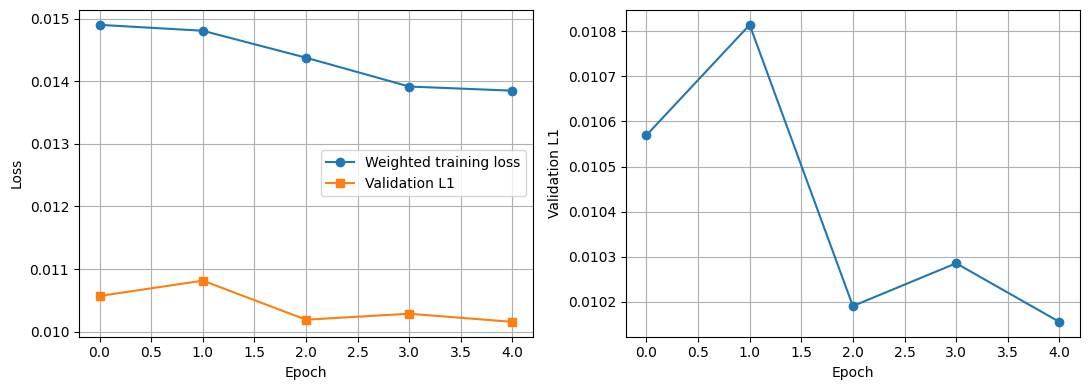

In [106]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["train_loss"], marker="o", label="Weighted training loss")
axes[0].plot(history["val_loss"], marker="s", label="Validation L1")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)
axes[1].plot(history["val_loss"], marker="o")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation L1")
axes[1].grid(True)
plt.tight_layout()
plt.show()

## 16. Load the best model and calculate PSNR/SSIM

For image restoration, PSNR and SSIM are more appropriate than classification accuracy. They are reference-based metrics and are calculated here only on the fixed synthetic validation pairs.

In [107]:
best_state = torch.load(BEST_CHECKPOINT, map_location=device, weights_only=False)
model.load_state_dict(best_state["model_state_dict"])
model.eval()
print("Best epoch:", best_state["epoch"])
print("Best validation L1:", best_state["val_loss"])


@torch.no_grad()
def evaluate_metrics(loader):
    results = {"model_psnr": [], "model_ssim": [], "input_psnr": [], "input_ssim": []}
    model.eval()
    for clean, flare, corrupted, mask, gamma in loader:
        clean_device = clean.to(device)
        corrupted_device = corrupted.to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            prediction, _ = model(corrupted_device)
        prediction = prediction.float().clamp(0, 1).cpu()

        for i in range(clean.shape[0]):
            gt = clean[i].permute(1, 2, 0).numpy().clip(0, 1)
            for tag, image in (("model", prediction[i]), ("input", corrupted[i])):
                image_np = image.permute(1, 2, 0).numpy().clip(0, 1)
                results[f"{tag}_psnr"].append(
                    peak_signal_noise_ratio(gt, image_np, data_range=1.0)
                )
                results[f"{tag}_ssim"].append(
                    structural_similarity(gt, image_np, channel_axis=2, data_range=1.0)
                )
    return {key: float(np.mean(values)) for key, values in results.items()}


val_results = evaluate_metrics(val_loader)
print(f"Input baseline: PSNR {val_results['input_psnr']:.2f} dB | SSIM {val_results['input_ssim']:.4f}")
print(f"U-Net output:   PSNR {val_results['model_psnr']:.2f} dB | SSIM {val_results['model_ssim']:.4f}")

Best epoch: 5
Best validation L1: 0.010155302522704005
Input baseline: PSNR 31.09 dB | SSIM 0.9609
U-Net output:   PSNR 35.23 dB | SSIM 0.9713


## 17. Visual comparison: corrupted input, model output, clean target

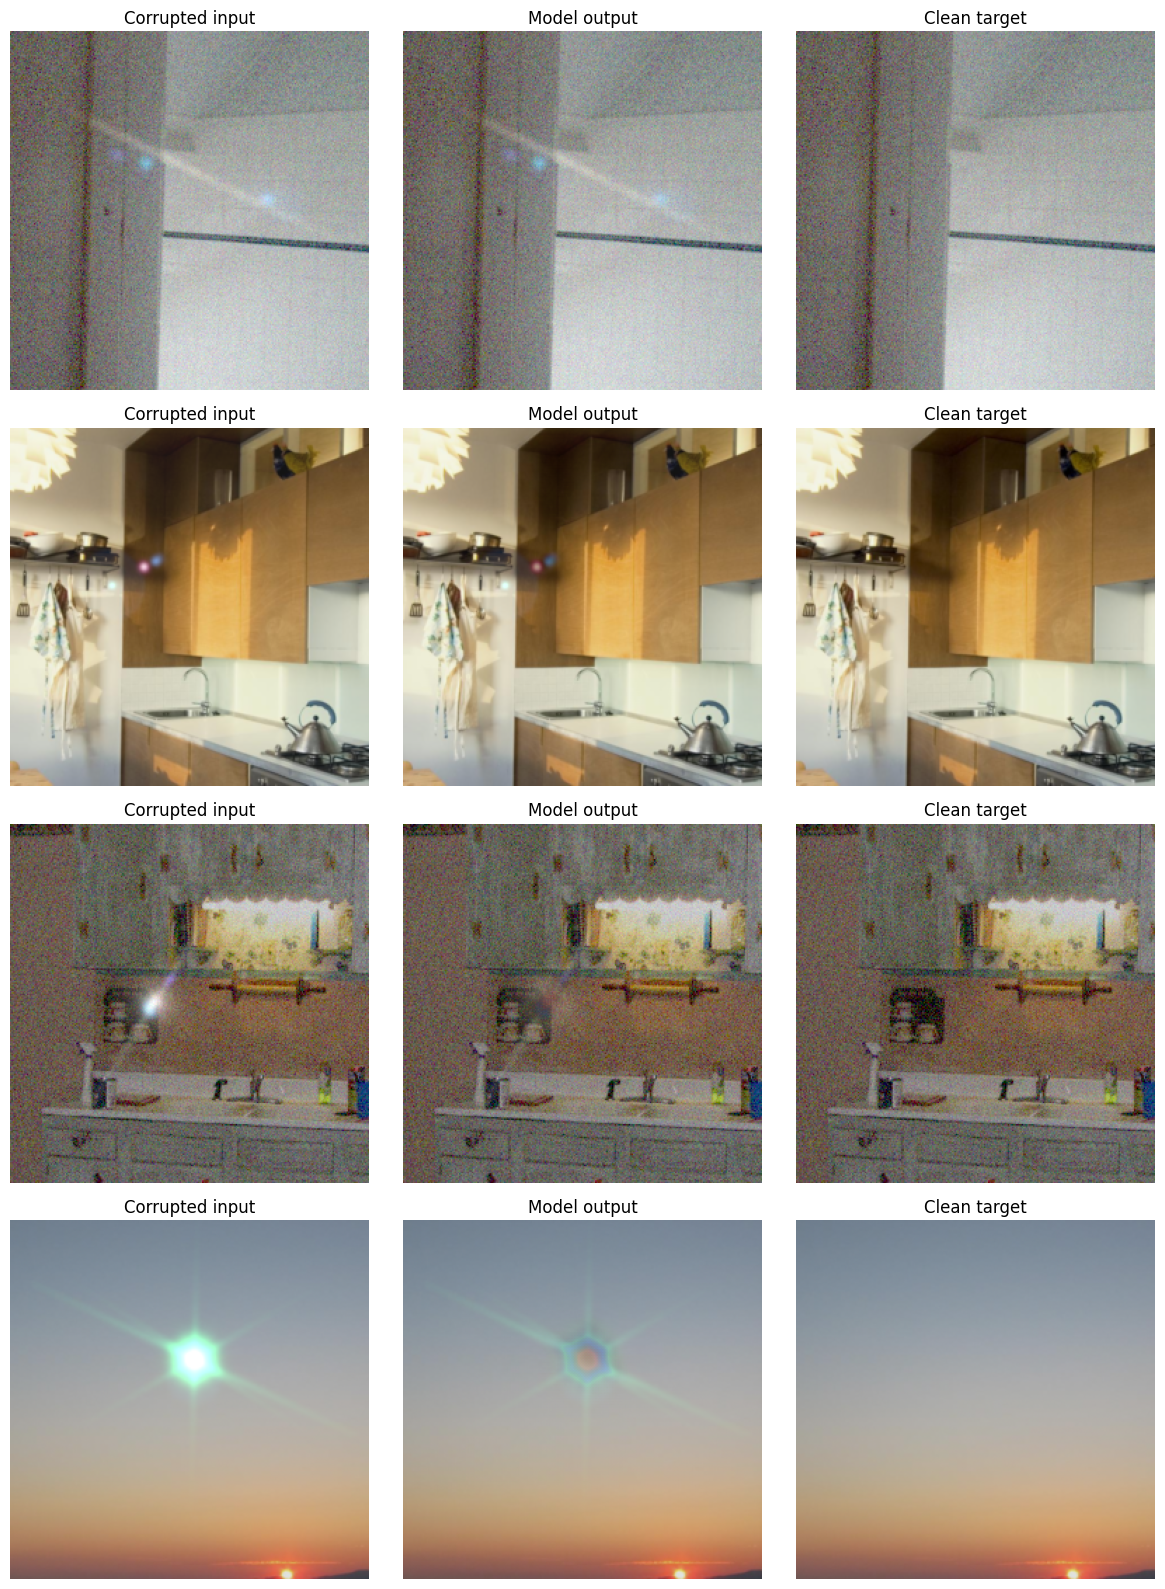

In [108]:
@torch.no_grad()
def show_predictions(number_of_images=4):
    model.eval()
    clean, flare, corrupted, mask, gamma = next(iter(val_loader))
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
        prediction, flare_estimate = model(corrupted[:number_of_images].to(device))
    prediction = prediction.float().clamp(0, 1).cpu()

    fig, axes = plt.subplots(number_of_images, 3, figsize=(12, 4 * number_of_images))
    if number_of_images == 1:
        axes = np.expand_dims(axes, axis=0)
    for i in range(number_of_images):
        images = [corrupted[i], prediction[i], clean[i]]
        titles = ["Corrupted input", "Model output", "Clean target"]
        for j, (image, title) in enumerate(zip(images, titles)):
            axes[i, j].imshow(image.permute(1, 2, 0).numpy().clip(0, 1))
            axes[i, j].set_title(title)
            axes[i, j].axis("off")
    plt.tight_layout()
    plt.show()

show_predictions(4)

## 18. Optional real paired-test evaluation

If the extracted Flare7K++ archive contains `test_data/real/input` and `test_data/real/gt`, evaluate those pairs separately. This is a held-out real-image check; do not mix these images into training. The code matches files by stem and reports how many pairs were found.

In [109]:
class RealPairDataset(Dataset):
    def __init__(self, input_dir, target_dir, image_size):
        allowed = {".png", ".jpg", ".jpeg", ".bmp"}
        input_files = {p.stem: p for p in Path(input_dir).iterdir()
                       if p.is_file() and p.suffix.lower() in allowed}
        target_files = {p.stem: p for p in Path(target_dir).iterdir()
                        if p.is_file() and p.suffix.lower() in allowed}
        self.keys = sorted(set(input_files) & set(target_files))
        self.input_files = input_files
        self.target_files = target_files
        self.transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.keys)

    def __getitem__(self, index):
        key = self.keys[index]
        with Image.open(self.target_files[key]) as im:
            clean = self.transform(im.convert("RGB"))
        with Image.open(self.input_files[key]) as im:
            corrupted = self.transform(im.convert("RGB"))
        return clean, corrupted


real_root = flare7k_dir.parent / "test_data" / "real"
real_input = real_root / "input"
real_gt = real_root / "gt"
real_results = None

if real_input.is_dir() and real_gt.is_dir():
    real_dataset = RealPairDataset(real_input, real_gt, IMAGE_SIZE)
    if len(real_dataset) > 0:
        real_loader = DataLoader(real_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
        # Evaluation helper for paired (clean, corrupted) batches.
        @torch.no_grad()
        def evaluate_real_pairs(loader):
            values = {"model_psnr": [], "model_ssim": [], "input_psnr": [], "input_ssim": []}
            model.eval()
            for clean, corrupted in loader:
                with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                    prediction, _ = model(corrupted.to(device))
                prediction = prediction.float().clamp(0, 1).cpu()
                for i in range(clean.shape[0]):
                    gt = clean[i].permute(1, 2, 0).numpy().clip(0, 1)
                    for label, image in (("model", prediction[i]), ("input", corrupted[i])):
                        image_np = image.permute(1, 2, 0).numpy().clip(0, 1)
                        values[f"{label}_psnr"].append(peak_signal_noise_ratio(gt, image_np, data_range=1.0))
                        values[f"{label}_ssim"].append(structural_similarity(
                            gt, image_np, channel_axis=2, data_range=1.0
                        ))
            return {k: float(np.mean(v)) for k, v in values.items()}

        real_results = evaluate_real_pairs(real_loader)
        print("Real paired test count:", len(real_dataset))
        print("Real input baseline:", real_results["input_psnr"], "dB | SSIM", real_results["input_ssim"])
        print("Real model result:  ", real_results["model_psnr"], "dB | SSIM", real_results["model_ssim"])
    else:
        print("Real test folders exist, but no matching filename stems were found.")
else:
    print("Real paired test folders not found. Skipping real-reference evaluation.")

Real test folders exist, but no matching filename stems were found.


## 19. Save final model and experiment results

In [110]:
FINAL_WEIGHTS = RUN_DIR / "flare_removal_unet_best_weights.pth"
torch.save(model.state_dict(), FINAL_WEIGHTS)

results = {
    "best_epoch": int(best_state["epoch"]),
    "best_validation_L1": float(best_state["val_loss"]),
    "synthetic_validation": val_results,
    "real_paired_test": real_results,
    "image_size": IMAGE_SIZE,
    "train_backgrounds": len(train_indices),
    "validation_backgrounds": len(val_indices),
    "epochs_completed": len(history["train_loss"])
}
(RUN_DIR / "results.json").write_text(json.dumps(results, indent=2))
print(json.dumps(results, indent=2))
print("Saved model:", FINAL_WEIGHTS)

{
  "best_epoch": 5,
  "best_validation_L1": 0.010155302522704005,
  "synthetic_validation": {
    "model_psnr": 35.23153519476703,
    "model_ssim": 0.9712532758712769,
    "input_psnr": 31.086809852353323,
    "input_ssim": 0.9609450697898865
  },
  "real_paired_test": null,
  "image_size": 256,
  "train_backgrounds": 4000,
  "validation_backgrounds": 500,
  "epochs_completed": 5
}
Saved model: /kaggle/working/flare_unet_experiment_2/flare_removal_unet_best_weights.pth


In [111]:
model.eval()

clean, flare, corrupted, mask, gamma = next(iter(val_loader))

clean = clean.to(device)
flare = flare.to(device)
corrupted = corrupted.to(device)

with torch.no_grad():
    clean_pred, flare_pred = model(corrupted)

actual_residual = corrupted - clean

print("Actual flare magnitude:",
      actual_residual.abs().mean().item())

print("Predicted flare magnitude:",
      flare_pred.abs().mean().item())

print("Input-target MAE:",
      (corrupted - clean).abs().mean().item())

print("Output-target MAE:",
      (clean_pred - clean).abs().mean().item())

print("Predicted correction MAE:",
      (corrupted - clean_pred).abs().mean().item())

Actual flare magnitude: 0.006602093577384949
Predicted flare magnitude: 0.0043214354664087296
Input-target MAE: 0.006602093577384949
Output-target MAE: 0.005053163971751928
Predicted correction MAE: 0.004321435000747442


In [112]:
print("Actual flare mean:", actual_residual.mean().item())
print("Predicted flare mean:", flare_pred.mean().item())

print("Actual flare std:", actual_residual.std().item())
print("Predicted flare std:", flare_pred.std().item())

print("Flare prediction MAE:",
      (flare_pred - actual_residual).abs().mean().item())

Actual flare mean: 0.006602093577384949
Predicted flare mean: 0.004319208674132824
Actual flare std: 0.031434476375579834
Predicted flare std: 0.023888304829597473
Flare prediction MAE: 0.005053164437413216


In [113]:
print("Training history keys:", history.keys())

for key, values in history.items():
    print(f"\n{key}:")
    print(values)

Training history keys: dict_keys(['train_loss', 'val_loss'])

train_loss:
[0.014903454332379624, 0.014809341929852962, 0.014378529832232744, 0.013917509930208325, 0.013850889273919165]

val_loss:
[0.010569332031533122, 0.01081426005763933, 0.010190414590761065, 0.010285321986768394, 0.010155302522704005]


In [114]:
import torch

magnitudes = []
stds = []

for i in range(50):
    clean, flare, corrupted, mask, gamma = fixed_val_dataset[i]

    actual_flare = corrupted - clean

    magnitudes.append(actual_flare.abs().mean().item())
    stds.append(actual_flare.std().item())

print("Mean flare magnitude:", sum(magnitudes) / len(magnitudes))
print("Mean flare standard deviation:", sum(stds) / len(stds))
print("Minimum flare magnitude:", min(magnitudes))
print("Maximum flare magnitude:", max(magnitudes))

Mean flare magnitude: 0.01758194995636586
Mean flare standard deviation: 0.03797493624035269
Minimum flare magnitude: 0.00012494981638155878
Maximum flare magnitude: 0.10757873207330704


In [115]:
model.eval()

baseline_errors = []
model_errors = []
actual_flare_stds = []
predicted_flare_stds = []

with torch.no_grad():
    for clean, flare, corrupted, mask, gamma in val_loader:
        clean = clean.to(device)
        corrupted = corrupted.to(device)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            clean_pred, flare_pred = model(corrupted)

        clean_pred = clean_pred.float().clamp(0, 1)

        baseline_errors.append(
            (corrupted - clean).abs().mean().item()
        )

        model_errors.append(
            (clean_pred - clean).abs().mean().item()
        )

        actual_flare_stds.append(
            (corrupted - clean).std().item()
        )

        predicted_flare_stds.append(
            flare_pred.float().std().item()
        )

print("Full validation comparison")
print("Baseline L1:", np.mean(baseline_errors))
print("Model L1:", np.mean(model_errors))
print("Actual flare std:", np.mean(actual_flare_stds))
print("Predicted flare std:", np.mean(predicted_flare_stds))

Full validation comparison
Baseline L1: 0.016186989021487533
Model L1: 0.010132991028949618
Actual flare std: 0.04145119191706181
Predicted flare std: 0.028581121822819112


In [116]:
model.eval()

results = []

with torch.no_grad():
    for clean, flare, corrupted, mask, gamma in val_loader:
        clean = clean.to(device)
        corrupted = corrupted.to(device)

        clean_pred, flare_pred = model(corrupted)
        clean_pred = clean_pred.clamp(0, 1)

        for i in range(clean.shape[0]):
            actual_flare = corrupted[i] - clean[i]

            strength = actual_flare.abs().mean().item()
            baseline_error = actual_flare.abs().mean().item()
            model_error = (
                clean_pred[i] - clean[i]
            ).abs().mean().item()

            results.append({
                "strength": strength,
                "baseline_error": baseline_error,
                "model_error": model_error
            })

import pandas as pd

results_df = pd.DataFrame(results)

results_df["flare_group"] = pd.qcut(
    results_df["strength"],
    q=3,
    labels=["Weak", "Medium", "Strong"]
)

print(
    results_df.groupby("flare_group", observed=True)[
        ["strength", "baseline_error", "model_error"]
    ].mean()
)

             strength  baseline_error  model_error
flare_group                                       
Weak         0.001110        0.001110     0.002473
Medium       0.008457        0.008457     0.006169
Strong       0.038948        0.038948     0.021736


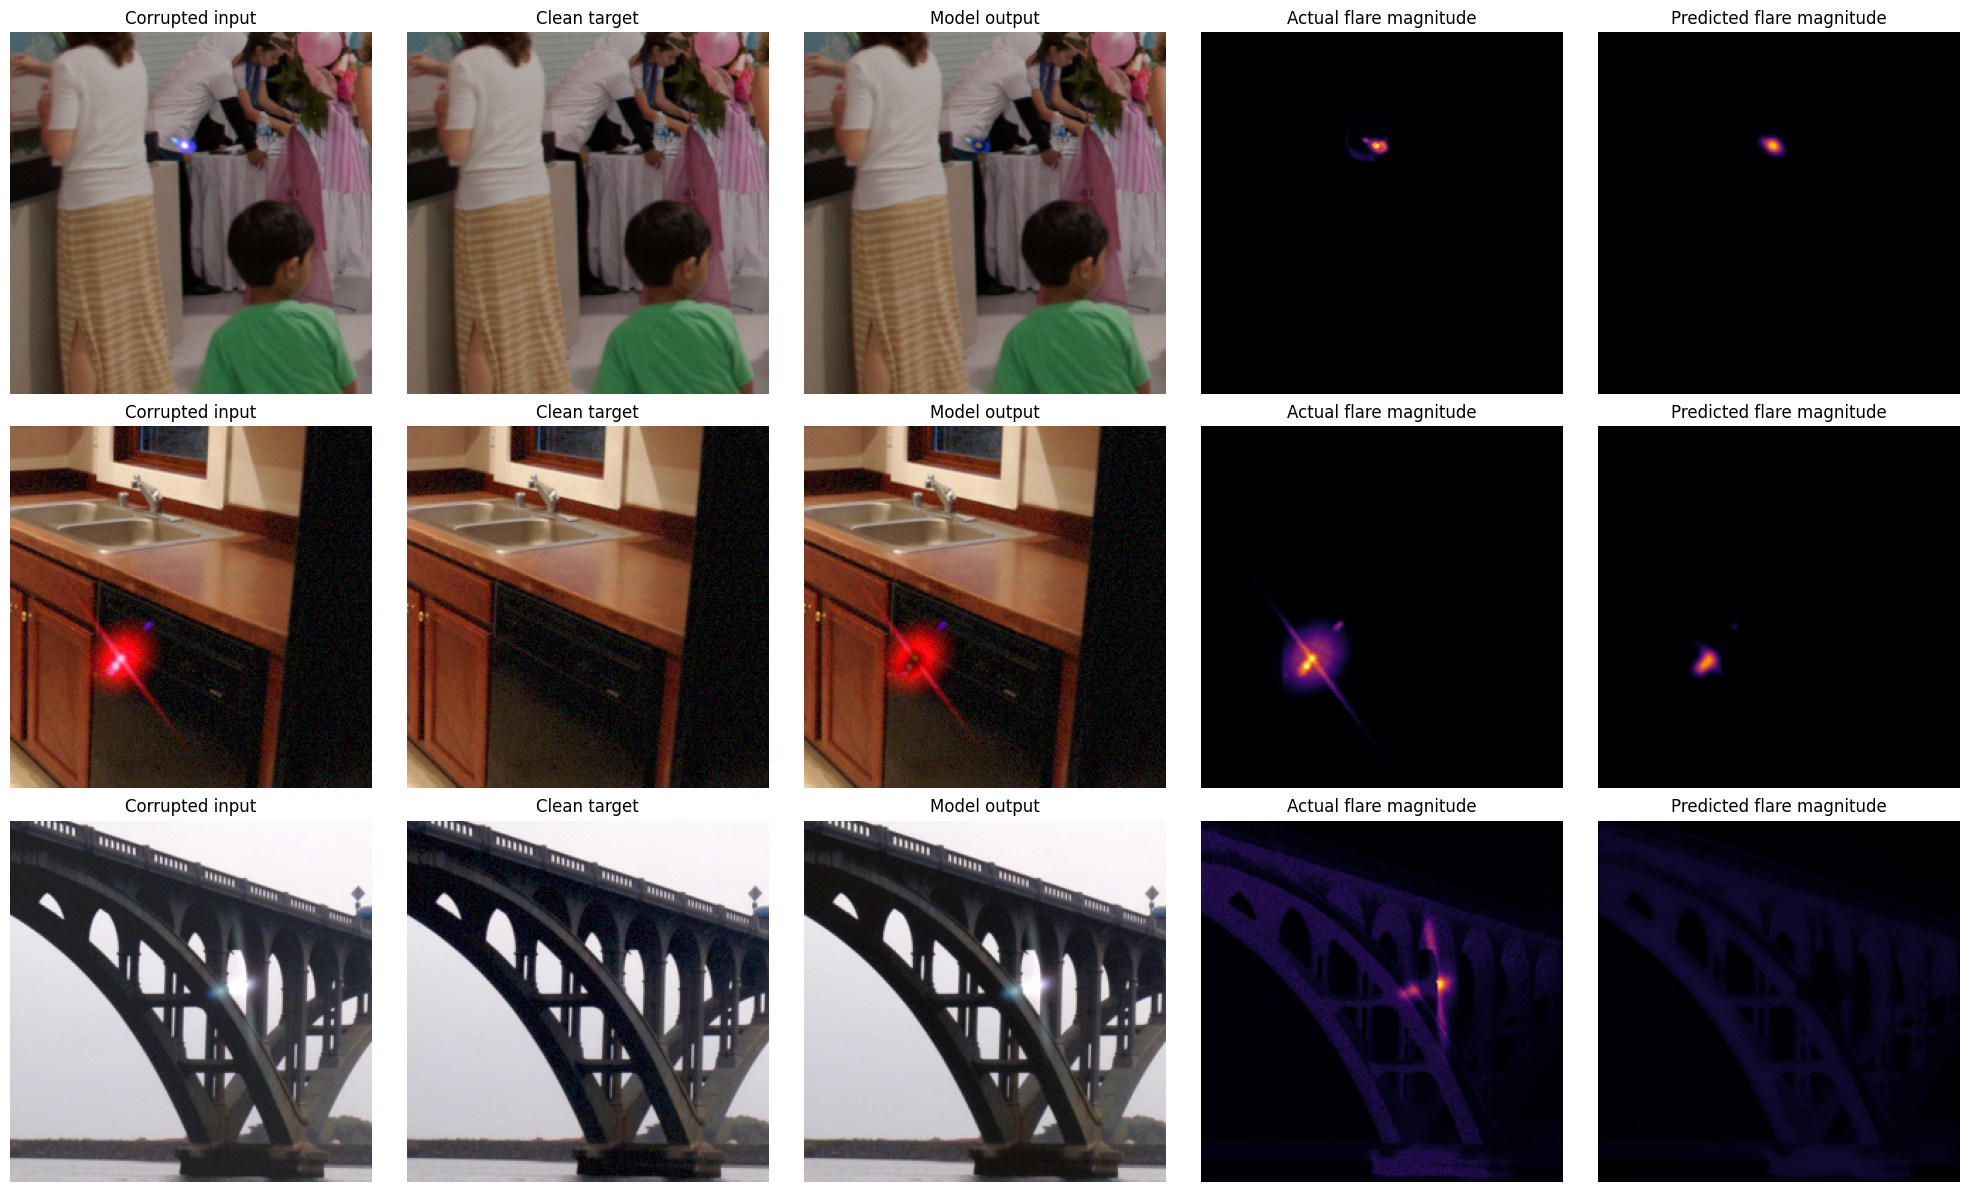

In [117]:
import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()

# Measure flare strength for every validation sample
flare_strengths = []

for i in range(len(fixed_val_dataset)):
    clean, flare, corrupted, mask, gamma = fixed_val_dataset[i]
    actual_flare = corrupted - clean
    flare_strengths.append(actual_flare.abs().mean().item())

flare_strengths = np.array(flare_strengths)

# Divide samples into three strength groups
q1, q2 = np.quantile(flare_strengths, [1/3, 2/3])

groups = {
    "Weak": np.where(flare_strengths <= q1)[0],
    "Medium": np.where(
        (flare_strengths > q1) & (flare_strengths <= q2)
    )[0],
    "Strong": np.where(flare_strengths > q2)[0]
}

# Select the median-strength sample from each group
selected = []

for name, indices in groups.items():
    median_idx = indices[
        np.argsort(flare_strengths[indices])[len(indices)//2]
    ]
    selected.append((name, int(median_idx)))

# Generate predictions
fig, axes = plt.subplots(3, 5, figsize=(20, 12))

for row, (group_name, idx) in enumerate(selected):
    clean, flare, corrupted, mask, gamma = fixed_val_dataset[idx]

    with torch.no_grad():
        prediction, flare_estimate = model(
            corrupted.unsqueeze(0).to(device)
        )

    prediction = prediction[0].float().clamp(0, 1).cpu()
    flare_estimate = flare_estimate[0].float().cpu()

    actual_residual = corrupted - clean

    # Residual magnitude maps
    actual_map = actual_residual.abs().mean(dim=0).numpy()
    predicted_map = flare_estimate.abs().mean(dim=0).numpy()

    # Shared scale for fair residual-map comparison
    vmax = max(actual_map.max(), predicted_map.max(), 1e-6)

    images = [
        corrupted.permute(1, 2, 0).numpy(),
        clean.permute(1, 2, 0).numpy(),
        prediction.permute(1, 2, 0).numpy(),
        actual_map,
        predicted_map
    ]

    titles = [
        "Corrupted input",
        "Clean target",
        "Model output",
        "Actual flare magnitude",
        "Predicted flare magnitude"
    ]

    for col, (image, title) in enumerate(zip(images, titles)):
        ax = axes[row, col]

        if col < 3:
            ax.imshow(np.clip(image, 0, 1))
        else:
            ax.imshow(image, cmap="inferno", vmin=0, vmax=vmax)

        ax.set_title(title)
        ax.axis("off")

    axes[row, 0].set_ylabel(
        f"{group_name}\nStrength: {flare_strengths[idx]:.4f}",
        fontsize=12
    )

plt.tight_layout()
plt.show()

In [123]:
from pathlib import Path
from IPython.display import display, FileLink
import os

model_path = Path(
    "/kaggle/working/Experiment2_COMPLETE.zip"
)

assert model_path.exists(), "Model file not found!"

os.chdir("/kaggle/working")

print("File size:", model_path.stat().st_size / (1024**2), "MB")

display(FileLink(
    "Experiment2_COMPLETE.zip",
    result_html_prefix="<b>Download your trained model: </b>"
))

File size: 47.8294792175293 MB


/kaggle/working/Experiment2_COMPLETE.zip

## Notes for the project report

- Task: supervised image-to-image restoration, mapping a flare-corrupted RGB image to its clean RGB target.
- Data: Flickr24K clean backgrounds combined with synthetic Flare7K++ scattering and reflective flare patterns using the official on-the-fly loader.
- Preprocessing: resize/crop to 256 × 256; loader converts images to tensors and applies its gamma/noise/flare synthesis operations.
- Split: disjoint clean-background indices; state the actual subset sizes used.
- Model: compact U-Net with skip connections.
- Objective: spatially weighted L1 reconstruction loss during training; ordinary L1 on the fixed validation set for checkpoint selection.
- Metrics: PSNR and SSIM on fixed synthetic validation pairs. These are not classification accuracy.
- Real captured test images without clean ground truth should be assessed qualitatively, not with reference-based PSNR/SSIM.
- A short subset run is a baseline. If the results are weak, measure epoch time first, then increase the training subset or epoch count gradually. Do not claim full-dataset training unless it was actually performed.
- Recovery: full checkpoint saved every 100 batches under `/kaggle/working/flare_unet_weighted_resume_v1`; resume restores model, optimizer, scheduler, AMP scaler, RNG state, batch position and history.
